Proszę wgrać trzy pliki MP3 (samogłoska, wyraz, zdanie):


Saving kamhunt-live-hip-hop-loop-81bpm-131102.mp3 to kamhunt-live-hip-hop-loop-81bpm-131102.mp3
Saving van_wiese-bass-wiggle-297877.mp3 to van_wiese-bass-wiggle-297877.mp3
Saving kamhunt-acoustic-guitar-loop-f-91bpm-132687 (1).mp3 to kamhunt-acoustic-guitar-loop-f-91bpm-132687 (1).mp3
Przetwarzanie pliku (Samogłoska): kamhunt-live-hip-hop-loop-81bpm-131102.mp3...
Przetwarzanie pliku (Wyraz): van_wiese-bass-wiggle-297877.mp3...
Przetwarzanie pliku (Zdanie): kamhunt-acoustic-guitar-loop-f-91bpm-132687 (1).mp3...


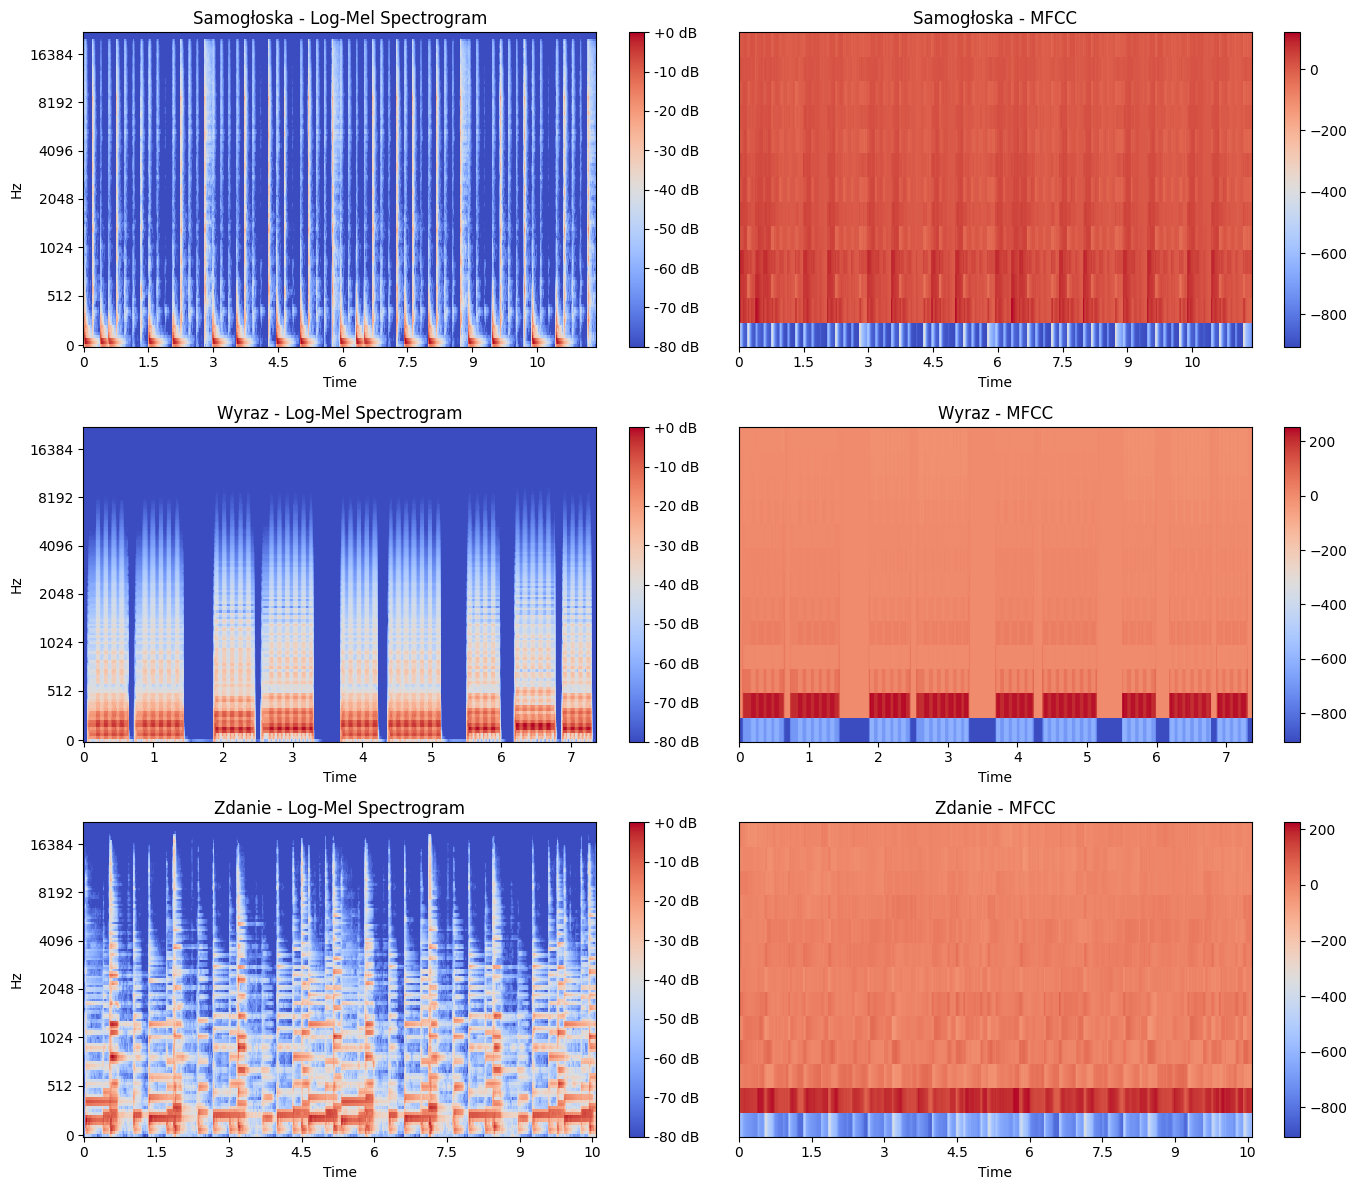

Generowanie analizy parametrów n_fft / hop_length...


/usr/local/lib/python3.13/dist-packages/librosa/feature/spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


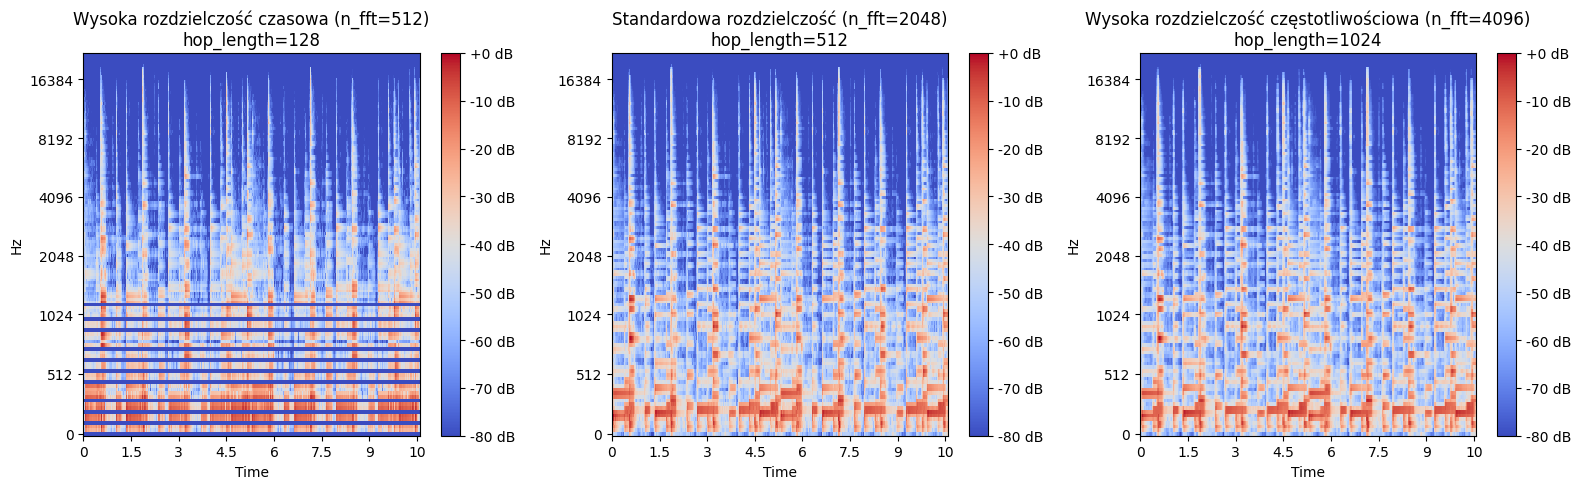

In [1]:
import os
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

print("Proszę wgrać trzy pliki MP3 (samogłoska, wyraz, zdanie):")
uploaded = files.upload()

audio_files = {}
for filename in uploaded.keys():
  if filename.endswith(".mp3"):
    if "samogłoska" in filename.lower() or len(audio_files) == 0:
      key = "Samogłoska"
    elif "wyraz" in filename.lower() or len(audio_files) == 1:
      key = "Wyraz"
    else:
      key = "Zdanie"
    audio_files[key] = filename

if len(audio_files) < 3:
  print(
      "Wgrano mniej niż 3 pliki lub nazwy nie zostały dopasowane automatycznie."
  )
  keys = ["Samogłoska", "Wyraz", "Zdanie"]
  audio_files = {}
  uploaded_names = list(uploaded.keys())
  for idx, name in enumerate(uploaded_names[:3]):
    audio_files[keys[idx]] = name

plt.figure(figsize=(14, 12))
i = 1

for name, filepath in audio_files.items():
  print(f"Przetwarzanie pliku ({name}): {filepath}...")

  y, sr = librosa.load(filepath, sr=None)

  mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
  log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

  mfcc = librosa.feature.mfcc(S=log_mel_spec, n_mfcc=13)

  plt.subplot(3, 2, i)
  librosa.display.specshow(
      log_mel_spec, sr=sr, x_axis="time", y_axis="mel", cmap="coolwarm"
  )
  plt.colorbar(format="%+2.0f dB")
  plt.title(f"{name} - Log-Mel Spectrogram")

  plt.subplot(3, 2, i + 1)
  librosa.display.specshow(mfcc, sr=sr, x_axis="time", cmap="coolwarm")
  plt.colorbar()
  plt.title(f"{name} - MFCC")

  i += 2

plt.tight_layout()
plt.show()

if "Zdanie" in audio_files:
  test_file = audio_files["Zdanie"]
elif len(audio_files) > 0:
  test_file = list(audio_files.values())[0]
else:
  test_file = None

if test_file and os.path.exists(test_file):
  print("Generowanie analizy parametrów n_fft / hop_length...")
  y, sr = librosa.load(test_file, sr=None)

  configs = [
      {
          "n_fft": 512,
          "hop_length": 128,
          "label": "Wysoka rozdzielczość czasowa (n_fft=512)",
      },
      {
          "n_fft": 2048,
          "hop_length": 512,
          "label": "Standardowa rozdzielczość (n_fft=2048)",
      },
      {
          "n_fft": 4096,
          "hop_length": 1024,
          "label": "Wysoka rozdzielczość częstotliwościowa (n_fft=4096)",
      },
  ]

  plt.figure(figsize=(16, 5))
  for idx, cfg in enumerate(configs):
    mel_spec = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=cfg["n_fft"], hop_length=cfg["hop_length"], n_mels=128
    )
    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

    plt.subplot(1, 3, idx + 1)
    librosa.display.specshow(
        log_mel_spec,
        sr=sr,
        hop_length=cfg["hop_length"],
        x_axis="time",
        y_axis="mel",
        cmap="coolwarm",
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title(f"{cfg['label']}\nhop_length={cfg['hop_length']}")

  plt.tight_layout()
  plt.show()

# Witamy w Colab

<div class="markdown-google-sans">
  <h2>Czym jest Colab?</h2>
</div>

Colab, lub inaczej „Colaboratory”, pozwala pisać i wykonywać kod w języku Python bezpośrednio w przeglądarce dzięki
- brakowi konieczności konfigurowania,
- Bezpłatny dostęp do GPU
- łatwemu udostępnianiu.

Colab może Ci ułatwić pracę niezależnie od tego, czy jesteś <strong>studentem</strong>, <strong>badaczem danych</strong> czy <strong>badaczem sztucznej inteligencji</strong>. Obejrzyj <a href="https://www.youtube.com/watch?v=inN8seMm7UI">Wprowadzenie do Colab</a> lub <a href="https://www.youtube.com/watch?v=rNgswRZ2C1Y">Funkcje Colab, które mogły Ci umknąć</a>, aby dowiedzieć się więcej, lub po prostu zjedź niżej i zacznij korzystać z tej usługi.

<div class="markdown-google-sans">

## <strong>Wprowadzenie</strong>
</div>

Dokument, który właśnie czytasz, nie jest statyczną stroną internetową tylko środowiskiem interaktywnym nazywanym <strong>notatnikiem Colab</strong> umożliwiającym pisanie i uruchamianie kodu.

Na przykład to jest <strong>komórka z kodem</strong> zawierająca krótki skrypt w języku Python, który oblicza wartość, zapisuje ją w zmiennej i drukuje wynik:

In [ ]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

Aby uruchomić kod w komórce powyżej, zaznacz ją przez kliknięcie, a potem kliknij przycisk uruchamiania po lewej stronie kodu lub użyj skrótu klawiszowego „Command/Ctrl + Enter”. Aby rozpocząć edytowanie kodu, wystarczy tylko kliknąć komórkę.

Zmiennych zdefiniowanych w jednej komórce możesz później używać w innych komórkach:

In [ ]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

W notatnikach Colab możesz łączyć ze sobą <strong>kod wykonywalny</strong> i <strong>tekst sformatowany</strong> w jeden dokument razem z <strong>obrazami</strong>, <strong>kodem HTML</strong>, <strong>kodem LaTeX</strong> itd. Gdy tworzysz własne notatniki Colab, są one przechowywane na Twoim koncie Dysku Google. Notatniki te możesz z łatwością udostępniać współpracownikom i znajomym, co pozwoli im zamieszczać w nich komentarze, a nawet edytować ich zawartość. Więcej dowiesz się z artykułu <a href="/notebooks/basic_features_overview.ipynb">Omówienie Colab</a>. Aby utworzyć nowy notatnik Colab, możesz skorzystać z menu „Plik” powyżej lub z tego linku: <a href="http://colab.research.google.com#create=true">utwórz nowy notatnik Colab</a>.

Notatniki Colab są notatnikami Jupyter hostowanymi przez Colab. Więcej informacji o projekcie Jupyter znajdziesz na <a href="https://www.jupyter.org">jupyter.org</a>.

## Usługa Google Colab już dostępna w VS Code
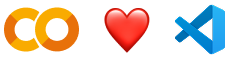

Wypróbuj nowe <a href="https://marketplace.visualstudio.com/items?itemName=Google.colab">rozszerzenie Google Colab</a> dla środowiska Visual Studio Code. Wystarczy kilka kliknięć:

*  W VS Code otwórz widok <strong><em>Rozszerzenia</em></strong> i wyszukaj „Google Colab”, aby zainstalować.
*  Otwórz selektor jądra, tworząc lub otwierając dowolny plik notatnika <code>.ipynb</code> w lokalnym obszarze roboczym i uruchamiając komórkę lub klikając przycisk <strong><em>Wybierz jądro</em></strong> w prawym górnym rogu.
*  Kliknij <strong><em>Colab</em></strong>, a następnie wybierz środowisko wykonawcze i zaloguj się na konto Google. To wszystko.

Więcej informacji znajdziesz w <a href="https://developers.googleblog.com/google-colab-is-coming-to-vs-code">tym poście na blogu</a>.

## Korzystaj z popularnych modeli AI dzięki Google-Colab-AI bez klucza interfejsu API
Wszyscy użytkownicy mogą korzystać z najpopularniejszych modeli LLM za pomocą biblioteki <code>google-colab-ai</code> języka Python, a użytkownicy wersji płatnej mają dostęp do większej liczby modeli. Dodatkowe informacje znajdziesz we <a href="https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/Getting_started_with_google_colab_ai.ipynb">wprowadzeniu do AI w Google Colab</a>.



In [ ]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")

## Poznaj interfejs Gemini API
Gemini API zapewnia dostęp do modeli Gemini stworzonych przez Google DeepMind. Modele Gemini są budowane od podstaw z myślą o multimodalności, dzięki czemu mogą łatwo pracować z tekstem, obrazami, kodem i dźwiękiem.

**Jak zacząć**
*  Otwórz <a href="https://aistudio.google.com/">Google AI Studio</a> i zaloguj się na swoje konto Google.
*  <a href="https://aistudio.google.com/app/apikey">Utwórz klucz interfejsu API</a>.
* Użyj krótkiego wprowadzenia do <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started.ipynb">Pythona</a> lub wywołaj interfejs API REST za pomocą <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/rest/Prompting_REST.ipynb">curl</a>.

**Odkryj zaawansowane możliwości Gemini**
*  Eksperymentuj z <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Image-out.ipynb">multimodalnymi wynikami</a> Gemini, mieszając tekst i obrazy w sposób iteracyjny.
*  Poznaj <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_LiveAPI.ipynb">multimodalny interfejs Live API</a> &#40;wersja demonstracyjna <a href="https://aistudio.google.com/live">tutaj</a>&#41;.
*  Dowiedz się, jak <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Spatial_understanding.ipynb&quot;">analizować obrazy i wykrywać przedmioty na zdjęciach</a> za pomocą Gemini &#40;dodatkowo jest też <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Spatial_understanding_3d.ipynb">wersja 3D</a>&#41;.
*  Odkryj możliwości <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_thinking.ipynb">modelu myślącego Gemini</a>, który potrafi rozwiązywać złożone zadania dzięki wewnętrznym procesom myślowym.
      
**Poznaj złożone przypadki użycia**
*  Użyj <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Search_grounding_for_research_report.ipynb">funkcji groundingu Gemini</a>, aby utworzyć raport o firmie na podstawie informacji wyszukanych przez model w internecie.
*  Wyodrębniaj <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Pdf_structured_outputs_on_invoices_and_forms.ipynb">faktury i dane z formularzy z plików PDF</a> w uporządkowany sposób.
*  Twórz <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Book_illustration.ipynb">ilustracje na podstawie całej książki</a>, korzystając z dużego okna kontekstu Gemini i Imagen.

Aby dowiedzieć się więcej, zapoznaj się ze <a href="https://github.com/google-gemini/cookbook">zbiorem Cookbook Gemini</a> lub wejdź na stronę <a href="https://ai.google.dev/docs/">dokumentacji API Gemini</a>.


Colab ma teraz funkcje AI oparte na <a href="https://gemini.google.com">Gemini</a>. Poniższy film zawiera informacje o tym, jak korzystać z tych funkcji, niezależnie od tego, czy dopiero zaczynasz przygodę z Pythonem, czy jesteś doświadczonym programistą.

<center>
  <a href="https://www.youtube.com/watch?v=V7RXyqFUR98" target="_blank">
  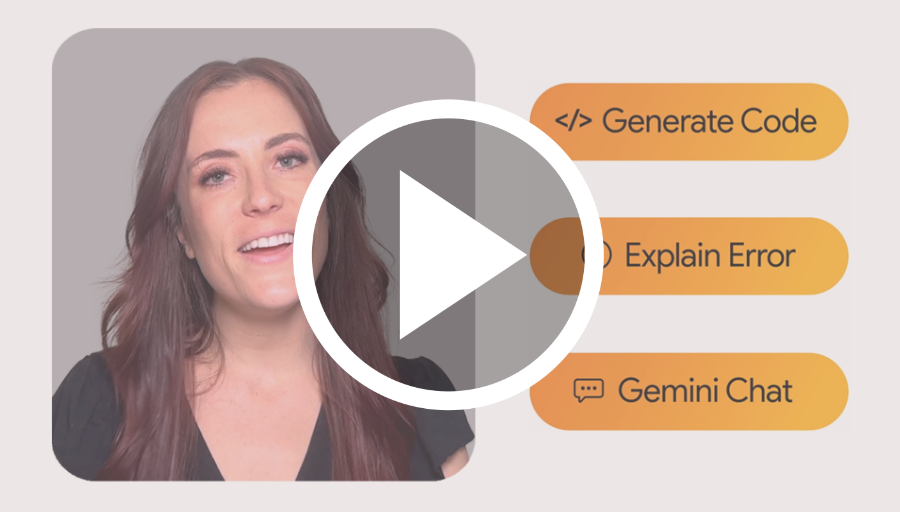
  </a>
</center>

<div class="markdown-google-sans">

## Badanie danych
</div>

Dzięki Colab możesz korzystać z wszystkich zalet popularnych bibliotek języka Python do analizowania i wizualizowania danych. Widoczna poniżej komórka z kodem korzysta z biblioteki <strong>numpy</strong> do generowania danych losowych oraz z biblioteki <strong>matplotlib</strong> do ich wizualizacji. Aby rozpocząć edytowanie kodu, wystarczy tylko kliknąć komórkę.

Do notatników Colab możesz importować własne dane z konta Dysku Google &#40;m.in. arkusze kalkulacyjne&#41; oraz z usługi GitHub i wielu innych źródeł. Aby dowiedzieć się więcej o importowaniu danych i sposobach użycia Colab do ich badania, skorzystaj z linków poniżej w sekcji <a href="#working-with-data">Praca z danymi</a>.

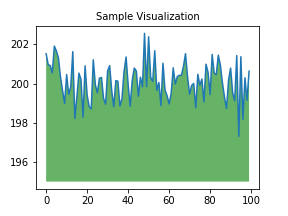

In [ ]:
import numpy as np
import IPython.display as display
from matplotlib import pyplot as plt
import io
import base64

ys = 200 + np.random.randn(100)
x = [x for x in range(len(ys))]

fig = plt.figure(figsize=(4, 3), facecolor='w')
plt.plot(x, ys, '-')
plt.fill_between(x, ys, 195, where=(ys > 195), facecolor='g', alpha=0.6)
plt.title("Sample Visualization", fontsize=10)

data = io.BytesIO()
plt.savefig(data)
image = F"data:image/png;base64,{base64.b64encode(data.getvalue()).decode()}"
alt = "Sample Visualization"
display.display(display.Markdown(F"""![{alt}]({image})"""))
plt.close(fig)

Notatniki Colab uruchamiają kod na serwerach Google w chmurze, co oznacza, że możesz korzystać z mocy obliczeniowej sprzętu Google, w tym z <a href="#using-accelerated-hardware">układów GPU i TPU</a>, niezależnie od konfiguracji swojego komputera. Potrzebujesz tylko przeglądarki.

Jeśli na przykład chcesz przyspieszyć działanie kodu <strong>pandas</strong>, możesz przełączyć się na środowisko wykonawcze GPU i użyć bibliotek takich jak <a href="https://rapids.ai/cudf-pandas">RAPIDS cuDF</a>, które zapewniają przyspieszenie bez konieczności wprowadzania zmian w kodzie.

Aby dowiedzieć się więcej o przyspieszaniu działania kodu pandas w Colab, zapoznaj się z <a href="https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_colab_demo.ipynb">10-minutowym przewodnikiem</a> lub <a href="https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_stocks_demo.ipynb">demonstracją analizy danych z amerykańskiej giełdy papierów wartościowych</a>.

<div class="markdown-google-sans">

## Systemy uczące się
</div>

Dzięki Colab możesz zaimportować zbiór danych graficznych, przeszkolić na nim klasyfikator obrazów i ocenić model — wystarczy wpisać <a href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/quickstart/beginner.ipynb">kilka wierszy kodu</a>.

Usługa Colab jest bardzo chętnie wykorzystywana w branży systemów uczących się do takich zastosowań jak:
- wprowadzenie do platformy TensorFlow,
- tworzenie i szkolenie sieci neuronowych,
- eksperymentowanie z układami TPU,
- rozpowszechnianie badań nad sztuczną inteligencją,
- tworzenie samouczków.

Aby zobaczyć przykładowe notatniki Colab, które ukazują zastosowania systemów uczących się, <a href="#machine-learning-examples">kliknij tutaj</a>.

<div class="markdown-google-sans">

## Więcej zasobów

### Praca z notatnikami w Colab

</div>

- [Omówienie Colab](/notebooks/basic_features_overview.ipynb)
- [Wprowadzenie do języka Markdown](/notebooks/markdown_guide.ipynb)
- [Importowanie bibliotek i instalowanie zależności](/notebooks/snippets/importing_libraries.ipynb)
- [Zapisywanie i wczytywanie notatników w usłudze GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Formularze interaktywne](/notebooks/forms.ipynb)
- [Widżety interaktywne](/notebooks/widgets.ipynb)

<div class="markdown-google-sans">

<a name="working-with-data"></a>
### Praca z danymi
</div>

- [Wczytywanie danych: Dysk, Arkusze i Google Cloud Storage](/notebooks/io.ipynb)
- [Wykresy: wizualizacja danych](/notebooks/charts.ipynb)
- [Wprowadzenie do BigQuery](/notebooks/bigquery.ipynb)

<div class="markdown-google-sans">

### Uczenie maszynowe

<div>

Oto kilka notatników dotyczących uczenia maszynowego, w tym szkolenie internetowe Google na ten temat. Więcej możesz znaleźć na <a href="https://developers.google.com/machine-learning/crash-course/">stronie szkolenia</a>.
- [Wprowadzenie do Pandas DataFrame](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Wprowadzenie do RAPIDS cuDF na potrzeby przyspieszenia biblioteki pandas](https://nvda.ws/rapids-cudf)
- [Pierwsze kroki z trybem akceleratora w cuML](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)

<div class="markdown-google-sans">

<a name="using-accelerated-hardware"></a>
### Korzystanie z akceleracji sprzętowej
</div>

- [Wytrenuj sieć CNN do klasyfikowania odręcznie napisanych cyfr w zbiorze danych MNIST przy użyciu interfejsu Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Trenowanie modelu Vision Transformer &#40;ViT&#41; do klasyfikacji obrazów za pomocą JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Klasyfikacja tekstu za pomocą modelu językowego transformera z użyciem JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<div class="markdown-google-sans">

<a name="machine-learning-examples"></a>

### Przykłady

</div>

- <a href="https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html">Trenowanie modelu językowego miniGPT za pomocą JAX AI Stack</a>
- <a href="https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb">Dostrojenie LoRA/QLoRA dla LLM przy użyciu Tunix</a>
- <a href="https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/">Dostrajanie konkretnych parametrów modelu Gemma z użyciem LoRA i QLoRA</a>
- <a href="https://keras.io/keras_hub/guides/hugging_face_keras_integration/">Wczytywanie punktów kontrolnych z biblioteki Transformers na platformie Hugging Face</a>
- <a href="https://keras.io/guides/int8_quantization_in_keras/">Kwantyzacja 8-bitowa liczb całkowitych w Keras</a>
- <a href="https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/">Trenowanie i wnioskowanie z użyciem typu Float8 w prostym modelu transformera</a>
- <a href="https://keras.io/keras_hub/guides/transformer_pretraining/">Wstępne trenowanie transformera od podstaw z użyciem KerasHub</a>
- <a href="https://keras.io/examples/vision/mnist_convnet/">Prosta sieć konwolucyjna MNIST</a>
- <a href="https://keras.io/examples/vision/image_classification_from_scratch/">Klasyfikacja obrazów od podstaw z użyciem Keras 3</a>
- <a href="https://keras.io/keras_hub/guides/classification_with_keras_hub/">Klasyfikacja obrazów z użyciem KerasHub</a>
